<a href="https://colab.research.google.com/github/phamquocan14102006/ThucHanhHocMay-2045240006/blob/main/PhamQuocAn_BTVN_Tuan1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. MÔ HÌNH ĐƠN GIẢN (15 mẫu, nhiễu thấp)
   - Phương trình : Giá = 42.86 * Diện_tích + 439.62
   - R2 Score     : 0.9956 | RMSE: 61.45 triệu VND
   - Dự đoán 72m2 : 3525.88 triệu VND

2. TĂNG DỮ LIỆU & ĐỘ NHIỄU CAO (500 mẫu, nhiễu std = 600)
   - Phương trình : Giá = 45.80 * Diện_tích + 237.00
   - R2 Score     : 0.8869 | RMSE: 579.79 triệu VND

3. MÔ HÌNH HỒI QUY ĐA BIẾN (4 biến đầu vào)
   - Hệ số Dien_tich      :    45.08
   - Hệ số So_phong_ngu   :   186.41
   - Hệ số Khoang_cach_TT :   -96.29
   - Hệ số Tuoi_nha       :   -24.71
   - Hệ số chặn (Intercept):   786.75
   - R2 Score              : 0.9953 | RMSE: 115.65 triệu VND



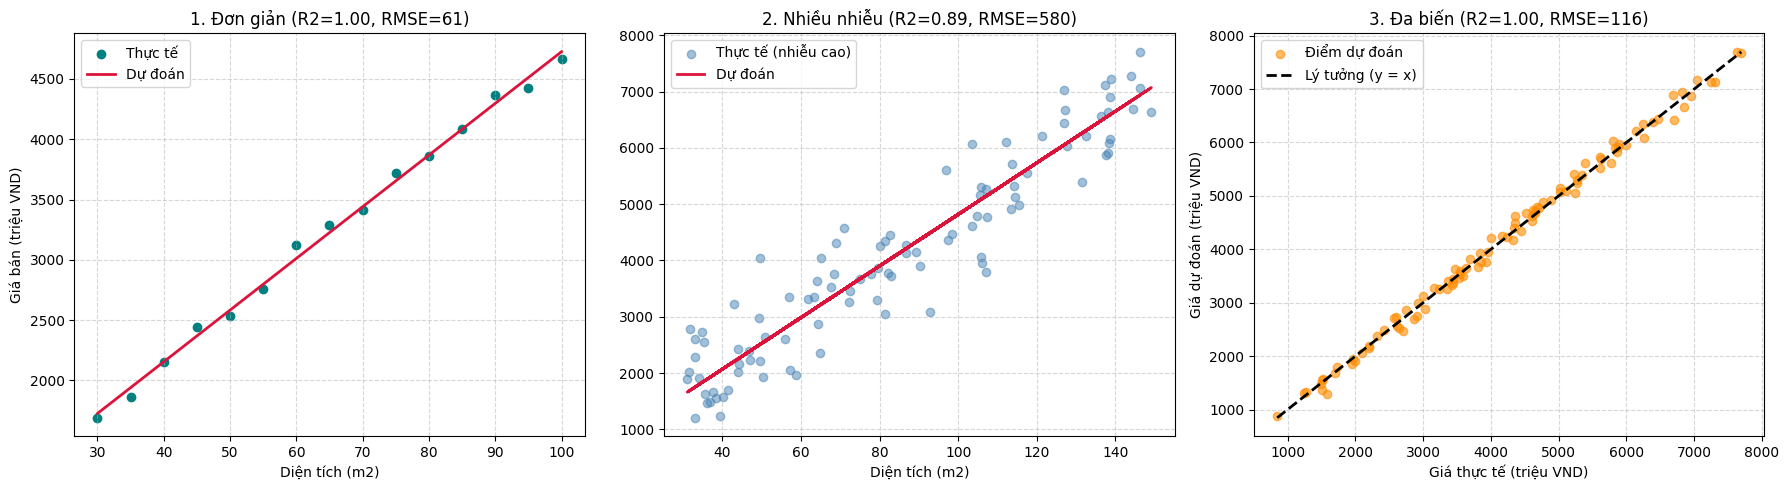

In [6]:
#btolop1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# Cố định seed để tái lập kết quả đồng nhất
np.random.seed(42)

# ==============================================================================
# BƯỚC 1: MÔ HÌNH HỒI QUY TUYẾN TÍNH ĐƠN GIẢN (DỮ LIỆU NHỎ, ÍT NHIỄU)
# ==============================================================================
dien_tich_1 = np.array([30, 35, 40, 45, 50, 55, 60, 65, 70, 75, 80, 85, 90, 95, 100]).reshape(-1, 1)
gia_ban_1 = 45 * dien_tich_1.flatten() + 300 + np.random.normal(0, 80, size=len(dien_tich_1))

model_1 = LinearRegression()
model_1.fit(dien_tich_1, gia_ban_1)
y_pred_1 = model_1.predict(dien_tich_1)

r2_1 = r2_score(gia_ban_1, y_pred_1)
rmse_1 = np.sqrt(mean_squared_error(gia_ban_1, y_pred_1))

print("1. MÔ HÌNH ĐƠN GIẢN (15 mẫu, nhiễu thấp)")
print(f"   - Phương trình : Giá = {model_1.coef_[0]:.2f} * Diện_tích + {model_1.intercept_:.2f}")
print(f"   - R2 Score     : {r2_1:.4f} | RMSE: {rmse_1:.2f} triệu VND")
print(f"   - Dự đoán 72m2 : {model_1.predict([[72]])[0]:.2f} triệu VND\n")


# ==============================================================================
# BƯỚC 2: TĂNG SỐ LƯỢNG DỮ LIỆU (500 MẪU) & ĐỘ NHIỄU CAO
# ==============================================================================
n_samples = 500
X_2 = np.random.uniform(30, 150, size=(n_samples, 1))
y_2 = 45 * X_2.flatten() + 300 + np.random.normal(0, 600, size=n_samples) # Nhiễu std = 600

X_train_2, X_test_2, y_train_2, y_test_2 = train_test_split(X_2, y_2, test_size=0.2, random_state=42)

model_2 = LinearRegression()
model_2.fit(X_train_2, y_train_2)
y_pred_2 = model_2.predict(X_test_2)

r2_2 = r2_score(y_test_2, y_pred_2)
rmse_2 = np.sqrt(mean_squared_error(y_test_2, y_pred_2))

print("2. TĂNG DỮ LIỆU & ĐỘ NHIỄU CAO (500 mẫu, nhiễu std = 600)")
print(f"   - Phương trình : Giá = {model_2.coef_[0]:.2f} * Diện_tích + {model_2.intercept_:.2f}")
print(f"   - R2 Score     : {r2_2:.4f} | RMSE: {rmse_2:.2f} triệu VND\n")


# ==============================================================================
# BƯỚC 3: THÊM CÁC BIẾN ĐẦU VÀO KHÁC (HỒI QUY ĐA BIẾN)
# ==============================================================================
dien_tich_3 = np.random.uniform(30, 150, n_samples)
so_phong_ngu = np.random.randint(1, 6, n_samples)
khoang_cach_tt = np.random.uniform(1, 20, n_samples)
tuoi_nha = np.random.randint(0, 30, n_samples)

gia_ban_3 = (
    45 * dien_tich_3
    + 180 * so_phong_ngu
    - 95 * khoang_cach_tt
    - 25 * tuoi_nha
    + 800
    + np.random.normal(0, 120, n_samples)
)

df = pd.DataFrame({
    'Dien_tich': dien_tich_3,
    'So_phong_ngu': so_phong_ngu,
    'Khoang_cach_TT': khoang_cach_tt,
    'Tuoi_nha': tuoi_nha,
    'Gia_ban': gia_ban_3
})

X_3 = df[['Dien_tich', 'So_phong_ngu', 'Khoang_cach_TT', 'Tuoi_nha']]
y_3 = df['Gia_ban']

X_train_3, X_test_3, y_train_3, y_test_3 = train_test_split(X_3, y_3, test_size=0.2, random_state=42)

model_3 = LinearRegression()
model_3.fit(X_train_3, y_train_3)
y_pred_3 = model_3.predict(X_test_3)

r2_3 = r2_score(y_test_3, y_pred_3)
rmse_3 = np.sqrt(mean_squared_error(y_test_3, y_pred_3))

print("3. MÔ HÌNH HỒI QUY ĐA BIẾN (4 biến đầu vào)")
for col, coef in zip(X_3.columns, model_3.coef_):
    print(f"   - Hệ số {col:15}: {coef:8.2f}")
print(f"   - Hệ số chặn (Intercept): {model_3.intercept_:8.2f}")
print(f"   - R2 Score              : {r2_3:.4f} | RMSE: {rmse_3:.2f} triệu VND\n")


# ==============================================================================
# TRỰC QUAN HÓA SO SÁNH 3 GIAI ĐOẠN
# ==============================================================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Biểu đồ 1: Đơn giản
axes[0].scatter(dien_tich_1, gia_ban_1, color='teal', label='Thực tế')
axes[0].plot(dien_tich_1, y_pred_1, color='crimson', linewidth=2, label='Dự đoán')
axes[0].set_title(f'1. Đơn giản (R2={r2_1:.2f}, RMSE={rmse_1:.0f})')
axes[0].set_xlabel('Diện tích (m2)')
axes[0].set_ylabel('Giá bán (triệu VND)')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Biểu đồ 2: Nhiều dữ liệu & Nhiễu cao
axes[1].scatter(X_test_2, y_test_2, color='steelblue', alpha=0.5, label='Thực tế (nhiễu cao)')
axes[1].plot(X_test_2, y_pred_2, color='crimson', linewidth=2, label='Dự đoán')
axes[1].set_title(f'2. Nhiều nhiễu (R2={r2_2:.2f}, RMSE={rmse_2:.0f})')
axes[1].set_xlabel('Diện tích (m2)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

# Biểu đồ 3: Đa biến (Thực tế vs Dự đoán)
axes[2].scatter(y_test_3, y_pred_3, color='darkorange', alpha=0.6, label='Điểm dự đoán')
min_val, max_val = y_test_3.min(), y_test_3.max()
axes[2].plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=2, label='Lý tưởng (y = x)')
axes[2].set_title(f'3. Đa biến (R2={r2_3:.2f}, RMSE={rmse_3:.0f})')
axes[2].set_xlabel('Giá thực tế (triệu VND)')
axes[2].set_ylabel('Giá dự đoán (triệu VND)')
axes[2].legend()
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Hệ số chặn (intercept): -7.2917
Hệ số góc BMI (coef):     0.2716

5 mẫu đầu trên tập kiểm tra (BMI, Xác suất mắc bệnh, Nhãn dự đoán, Nhãn thật):
  BMI=20.30 | Prob=0.1446 | Pred=0 | True=0
  BMI=18.84 | Prob=0.1020 | Pred=0 | True=0
  BMI=19.80 | Prob=0.1285 | Pred=0 | True=0
  BMI=17.08 | Prob=0.0658 | Pred=0 | True=0
  BMI=24.58 | Prob=0.3504 | Pred=0 | True=0

Độ chính xác (Accuracy) trên tập kiểm tra: 0.8133 (81.33%)
Ma trận nhầm lẫn (Confusion Matrix):
 [[27  6]
 [ 8 34]]


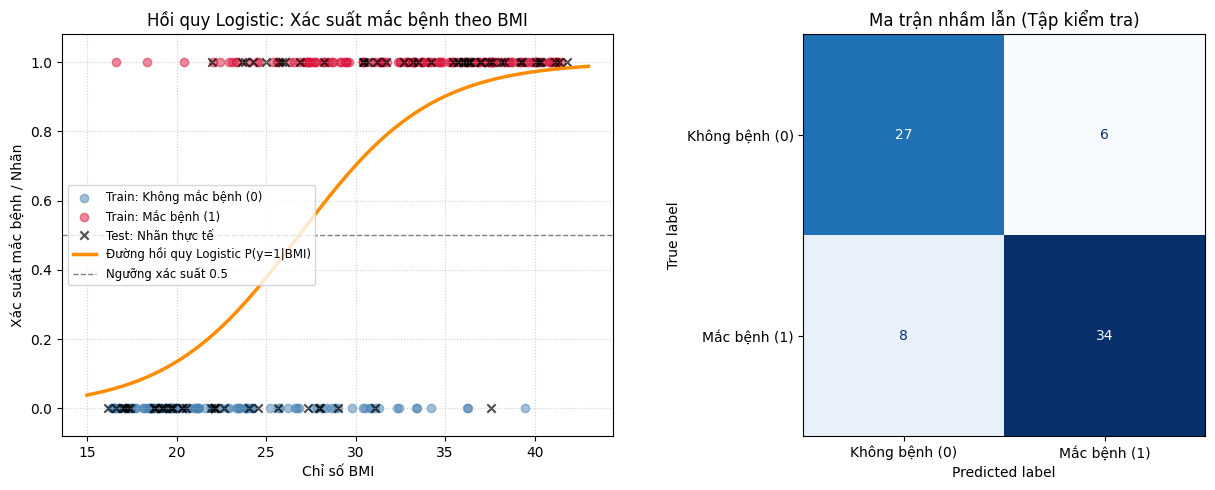

In [7]:
#btolop2
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# 1. Tạo dữ liệu mẫu giả lập dựa trên mối liên hệ logic giữa BMI và khả năng mắc bệnh
rng = np.random.default_rng(42)
n_samples = 300

# Sinh ngẫu nhiên BMI trong khoảng [16, 42]
bmi = rng.uniform(16.0, 42.0, size=n_samples)

# Xác suất thực tế tăng theo BMI qua hàm sigmoid (điểm chuyển tiếp quanh BMI = 27)
log_odds = -8.1 + 0.3 * bmi
true_prob = 1.0 / (1.0 + np.exp(-log_odds))
disease = rng.binomial(n=1, p=true_prob)

# Chuyển BMI thành ma trận 2D (n_samples, 1) cho scikit-learn
X = bmi.reshape(-1, 1)
y = disease

# Chia tập huấn luyện (75%) và tập kiểm tra (25%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# 2 & 3. Khởi tạo và huấn luyện mô hình hồi quy logistic
model = LogisticRegression()
model.fit(X_train, y_train)

# 4. Dự đoán xác suất mắc bệnh (lớp 1) và nhãn (0/1) trên tập kiểm tra
y_prob_test = model.predict_proba(X_test)[:, 1]
y_pred_test = model.predict(X_test)

print(f"Hệ số chặn (intercept): {model.intercept_[0]:.4f}")
print(f"Hệ số góc BMI (coef):     {model.coef_[0][0]:.4f}")
print("\n5 mẫu đầu trên tập kiểm tra (BMI, Xác suất mắc bệnh, Nhãn dự đoán, Nhãn thật):")
for i in range(5):
    print(
        f"  BMI={X_test[i, 0]:5.2f} | Prob={y_prob_test[i]:.4f} | "
        f"Pred={y_pred_test[i]} | True={y_test[i]}"
    )

# 5. Đánh giá mô hình qua độ chính xác (Accuracy) và ma trận nhầm lẫn (Confusion Matrix)
acc = accuracy_score(y_test, y_pred_test)
cm = confusion_matrix(y_test, y_pred_test)

print(f"\nĐộ chính xác (Accuracy) trên tập kiểm tra: {acc:.4f} ({acc * 100:.2f}%)")
print("Ma trận nhầm lẫn (Confusion Matrix):\n", cm)

# 6. Trực quan hóa dữ liệu và đường hồi quy logistic
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Biểu đồ 1: Dữ liệu thực tế + Đường cong xác suất hồi quy logistic
bmi_grid = np.linspace(15, 43, 300).reshape(-1, 1)
prob_grid = model.predict_proba(bmi_grid)[:, 1]

axes[0].scatter(
    X_train[y_train == 0], y_train[y_train == 0],
    color="steelblue", alpha=0.5, label="Train: Không mắc bệnh (0)"
)
axes[0].scatter(
    X_train[y_train == 1], y_train[y_train == 1],
    color="crimson", alpha=0.5, label="Train: Mắc bệnh (1)"
)
axes[0].scatter(
    X_test, y_test,
    color="black", marker="x", alpha=0.7, label="Test: Nhãn thực tế"
)
axes[0].plot(
    bmi_grid, prob_grid,
    color="darkorange", linewidth=2.5, label="Đường hồi quy Logistic P(y=1|BMI)"
)
axes[0].axhline(0.5, color="gray", linestyle="--", linewidth=1, label="Ngưỡng xác suất 0.5")

axes[0].set_title("Hồi quy Logistic: Xác suất mắc bệnh theo BMI")
axes[0].set_xlabel("Chỉ số BMI")
axes[0].set_ylabel("Xác suất mắc bệnh / Nhãn")
axes[0].set_ylim(-0.08, 1.08)
axes[0].legend(loc="center left", fontsize=8.5)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Biểu đồ 2: Ma trận nhầm lẫn
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Không bệnh (0)", "Mắc bệnh (1)"])
disp.plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Ma trận nhầm lẫn (Tập kiểm tra)")

plt.tight_layout()
plt.show()

In [8]:
#btvn1
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

noise_levels = [5, 20, 50, 100]

for noise in noise_levels:
    X, y = make_regression(
        n_samples=300,
        n_features=1,
        noise=noise,
        random_state=42
    )
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    print(f"Noise = {noise:3d} | MSE = {mse:10.2f} | R2 = {r2:.4f}")

Noise =   5 | MSE =      26.67 | R2 = 0.9712
Noise =  20 | MSE =     426.75 | R2 = 0.6960
Noise =  50 | MSE =    2667.19 | R2 = 0.2940
Noise = 100 | MSE =   10668.78 | R2 = 0.1061


In [9]:
#btvn2
import numpy as np
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix
from sklearn.model_selection import train_test_split

X, y = make_classification(
    n_samples=500,
    n_features=5,
    n_informative=3,
    random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

clf = LogisticRegression()
clf.fit(X_train, y_train)

# Xác suất thuộc lớp 1
y_prob = clf.predict_proba(X_test)[:, 1]

for threshold in [0.5, 0.6, 0.7]:
    y_pred_custom = (y_prob >= threshold).astype(int)
    acc = accuracy_score(y_test, y_pred_custom)
    prec = precision_score(y_test, y_pred_custom, zero_division=0)
    rec = recall_score(y_test, y_pred_custom, zero_division=0)
    pos_count = y_pred_custom.sum()

    print(f"\n--- Ngưỡng (threshold) = {threshold} ---")
    print(f"Số mẫu dự đoán lớp 1: {pos_count}/{len(y_pred_custom)}")
    print(f"Accuracy: {acc:.4f} | Precision: {prec:.4f} | Recall: {rec:.4f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_custom))


--- Ngưỡng (threshold) = 0.5 ---
Số mẫu dự đoán lớp 1: 69/125
Accuracy: 0.8320 | Precision: 0.8116 | Recall: 0.8750
Confusion Matrix:
 [[48 13]
 [ 8 56]]

--- Ngưỡng (threshold) = 0.6 ---
Số mẫu dự đoán lớp 1: 64/125
Accuracy: 0.8560 | Precision: 0.8594 | Recall: 0.8594
Confusion Matrix:
 [[52  9]
 [ 9 55]]

--- Ngưỡng (threshold) = 0.7 ---
Số mẫu dự đoán lớp 1: 59/125
Accuracy: 0.8320 | Precision: 0.8644 | Recall: 0.7969
Confusion Matrix:
 [[53  8]
 [13 51]]


In [11]:
#btvn3
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# 1. Tải dữ liệu giá nhà có sẵn trong scikit-learn (tránh lỗi thiếu file CSV)
housing = fetch_california_housing(as_frame=True)
df = housing.frame

target_col = "MedHouseVal"
X = df.drop(columns=[target_col])
y = df[target_col]

# 2. Phân chia tập huấn luyện (80%) và tập kiểm tra (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Huấn luyện mô hình Linear Regression và dự đoán trên tập kiểm tra
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4. Tính toán MSE và R2 score cho tập kiểm tra
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"MSE (Mean Squared Error): {mse:.4f}")
print(f"R2 Score: {r2:.4f}")

MSE (Mean Squared Error): 0.5559
R2 Score: 0.5758
